## DS340H Capstone HW3
Author: QiQi Li
Date : September 12, 2026

In [5]:
import pandas as pd
import matplotlib.pyplot as plt

In [2]:
df = pd.read_csv("food_establishment.csv")
df.head()

C:\Users\liqiq\AppData\Local\Temp\ipykernel_26472\2917323551.py:1: DtypeWarning: Columns (23) have mixed types. Specify dtype option on import or set low_memory=False.
  df = pd.read_csv("food_establishment.csv")


,businessname,dbaname,legalowner,namelast,namefirst,licenseno,issdttm,expdttm,licstatus,licensecat,...,violdttm,viol_status,status_date,comments,address,city,state,zip,property_id,location
0,1000 Degrees Pizza,NaN,KHOSLA VIPAN,Pasquriello LLC,Kenneth Pasquariello,313440,2017-08-14 12:49:37+00,2020-01-01 04:59:00+00,Inactive,FS,...,2018-03-20 14:54:25+00,Fail,NaN,One staff person without hair restraint. Provide,55 COURT ST,BOSTON,MA,2108.0,156226.0,"(42.35925954972639, -71.05890048027378)"
1,1000 Degrees Pizza,NaN,KHOSLA VIPAN,Pasquriello LLC,Kenneth Pasquariello,313440,2017-08-14 12:49:37+00,2020-01-01 04:59:00+00,Inactive,FS,...,2018-03-20 14:54:25+00,Fail,NaN,Caked on food debris on can opener blade. Clea...,55 COURT ST,BOSTON,MA,2108.0,156226.0,"(42.35925954972639, -71.05890048027378)"
2,1000 Degrees Pizza,NaN,KHOSLA VIPAN,Pasquriello LLC,Kenneth Pasquariello,313440,2017-08-14 12:49:37+00,2020-01-01 04:59:00+00,Inactive,FS,...,2018-03-20 14:54:25+00,Fail,NaN,Menu was redesigned allergy statement was remo...,55 COURT ST,BOSTON,MA,2108.0,156226.0,"(42.35925954972639, -71.05890048027378)"
3,1000 Degrees Pizza,NaN,KHOSLA VIPAN,Pasquriello LLC,Kenneth Pasquariello,313440,2017-08-14 12:49:37+00,2020-01-01 04:59:00+00,Inactive,FS,...,2018-08-08 15:54:00+00,Fail,NaN,Several dented cans found on storage shelves. ...,55 COURT ST,BOSTON,MA,2108.0,156226.0,"(42.35925954972639, -71.05890048027378)"
4,1000 Degrees Pizza,NaN,KHOSLA VIPAN,Pasquriello LLC,Kenneth Pasquariello,313440,2017-08-14 12:49:37+00,2020-01-01 04:59:00+00,Inactive,FS,...,2018-08-08 15:54:00+00,Fail,NaN,Wet wiping cloths found on counter tops . Remo...,55 COURT ST,BOSTON,MA,2108.0,156226.0,"(42.35925954972639, -71.05890048027378)"


In [4]:
df.nunique()

businessname      9439
dbaname            117
legalowner        2800
namelast          8818
namefirst         4073
licenseno        11351
issdttm          11211
expdttm            157
licstatus            3
licensecat           4
descript             4
result              20
resultdttm      198371
violation          462
viol_level           4
violdesc           454
violdttm        155184
viol_status          2
status_date      56314
comments        367366
address           4632
city                36
state                3
zip                 70
property_id       4510
location          4865
dtype: int64

Visualization 1 (line plot): Explore the frequency of recorded violations changed over time

In [ ]:
# convert time into datetime 
df['violdttm'] = pd.to_datetime(df['violdttm'],errors="coerce")

In [ ]:
# aggregate the violations by month
monthly_violation = (df.dropna(subset=['violdttm']).set_index("violdttm").resample("ME").size())

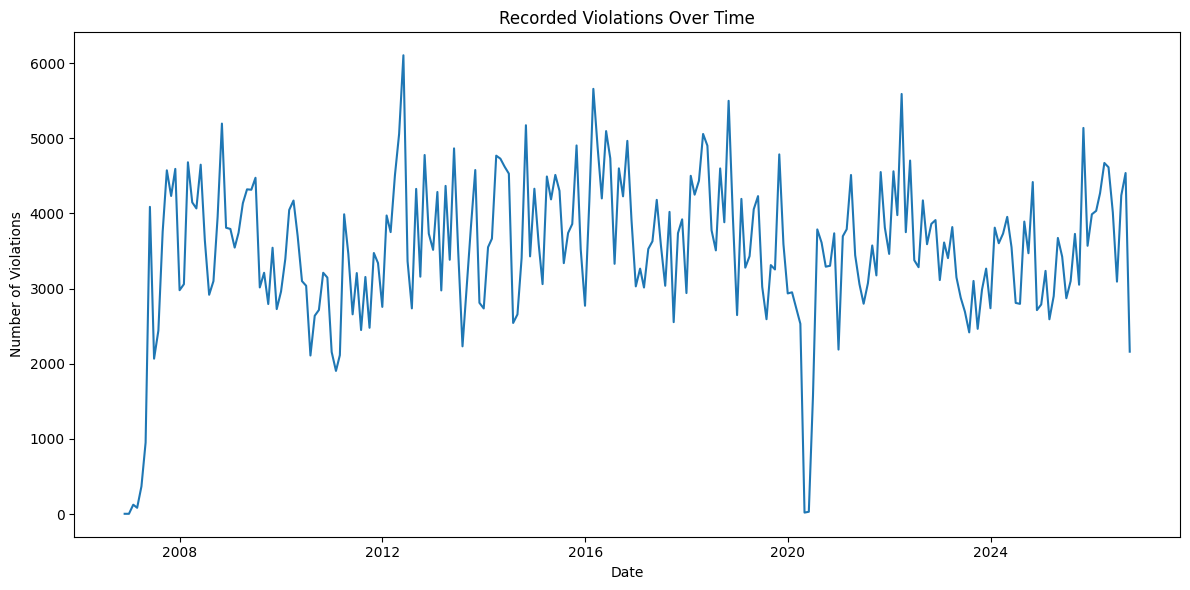

In [9]:
fig,ax = plt.subplots(figsize=(12,6))
ax.plot(monthly_violation.index,monthly_violation.values)

ax.set_title("Recorded Violations Over Time")
ax.set_xlabel("Date")
ax.set_ylabel("Number of Violations")

fig.tight_layout()

plt.savefig("violations_over_time.png",
dpi = 300)
plt.show()

Visualization 2 (Heat map) : explore whether the violation severity differ across license categories

In [19]:
heatmap_df = df[df["viol_level"].isin(["*", "**", "***"])]

heatmap_data = pd.crosstab(heatmap_df['licensecat'],heatmap_df['viol_level'],normalize = "index") *100

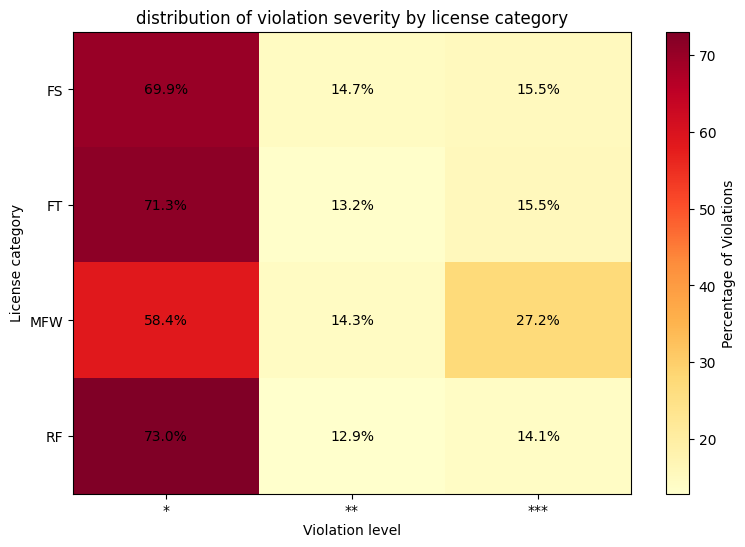

In [20]:
fig, ax = plt.subplots(figsize=(9,6))

im = ax.imshow(heatmap_data.values, aspect="auto", cmap="YlOrRd")

ax.set_xticks(range(len(heatmap_data.columns)))
ax.set_xticklabels(heatmap_data.columns)

ax.set_yticks(range(len(heatmap_data.index)))
ax.set_yticklabels(heatmap_data.index)

ax.set_xlabel("Violation level")
ax.set_ylabel("License category")
ax.set_title("distribution of violation severity by license category")

for i in range(len(heatmap_data.index)):
    for j in range(len(heatmap_data.columns)):
        ax.text(
            j, i,
            f"{heatmap_data.iloc[i, j]:.1f}%",
            ha="center",
            va="center"
        )

fig.colorbar(im, ax=ax, label="Percentage of Violations")


plt.savefig(
    "violation_heatmap.png",
    dpi=300,
)

plt.show()

In [17]:
print(df["licensecat"].value_counts())
print(df["viol_level"].value_counts())

licensecat
FS     442824
FT     342844
RF     109048
MFW      8411
Name: count, dtype: int64
viol_level
*       589584
***     128606
**      115891
1919         1
Name: count, dtype: int64


In [18]:
df.loc[df["viol_level"] == "1919",
       ["businessname", "licensecat", "violation", "viol_level",
        "violdesc", "violdttm"]]

,businessname,licensecat,violation,viol_level,violdesc,violdttm
178448,Cigar Masters,FS,02-3-305.11(2),1919,Food products protected against contamination(...,2015-07-01 13:01:00+00:00


I excluded one observation with a violation level of 1919 because all other non-missing observations were categorized as *, **, or ***, suggesting that 1919 was an anomalous value. The excluded observation represented 1 of 834,082 records with a non-missing violation level.

Visualization 3 (violin plot): Explore how the distribution of violation frequency differ across license categories.

In [22]:
violations_per_license = (df.groupby(['licenseno','licensecat']).size().reset_index(name='number_of_violations'))
violations_per_license

,licenseno,licensecat,number_of_violations
0,54,FT,3
1,4032,RF,97
2,4036,RF,338
3,17602,RF,25
4,17603,FS,18
...,...,...,...
11346,634682,FT,2
11347,635156,FT,1
11348,635638,FS,1
11349,635940,FT,1


In [26]:
categories = violations_per_license['licensecat'].dropna().unique()
categories

array(['FT', 'RF', 'FS', 'MFW'], dtype=object)

In [29]:
data = [violations_per_license.loc[violations_per_license['licensecat']==category, "number_of_violations"].values for category in categories]


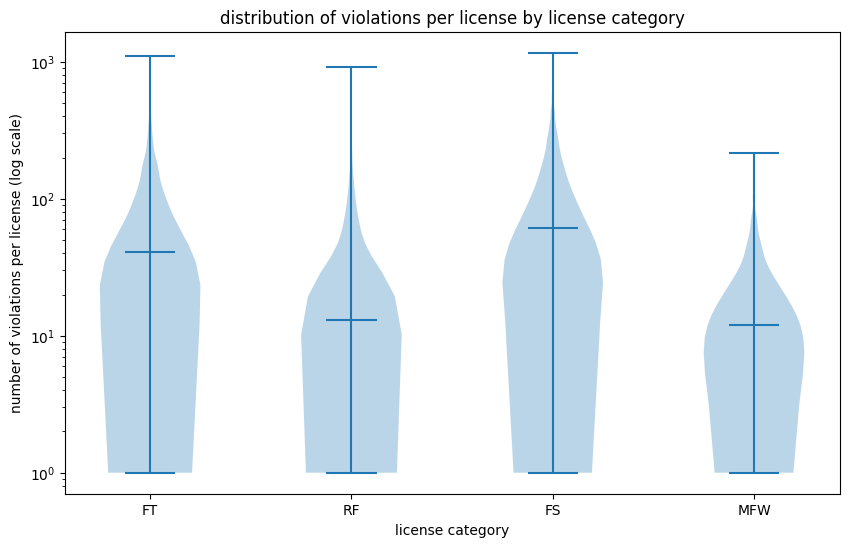

In [32]:
fig, ax = plt.subplots(figsize=(10,6))

ax.violinplot(data, showmedians=True)

ax.set_xticks(range(1,len(categories)+1))
ax.set_xticklabels(categories)

ax.set_yscale("log")
ax.set_xlabel("license category")
ax.set_ylabel("number of violations per license (log scale)")
ax.set_title('distribution of violations per license by license category')

plt.savefig("violations_violin.png",dpi=300)
plt.show()

Visualizations 4 (histogram) : Explore the distribution of license durations.

In [41]:
licenses = (
    df[["licenseno", "issdttm", "expdttm"]]
    .dropna()
    .drop_duplicates()
    .copy()
)

licenses["duration_days"] = (
    licenses["expdttm"] - licenses["issdttm"]
).dt.days

print("Unique license-date combinations:", len(licenses))
print(licenses["duration_days"].describe())
print(licenses["duration_days"].value_counts().head(20))
print("Negative durations:", (licenses["duration_days"] < 0).sum())

Unique license-date combinations: 11199
count    11199.000000
mean      1900.294401
std       1796.743539
min       -973.000000
25%        342.000000
50%       1381.000000
75%       2982.500000
max       5538.000000
Name: duration_days, dtype: float64
duration_days
 5439    85
 5433    58
 332     51
 5497    47
 5482    46
 5435    44
 5474    36
 5469    36
 5491    34
-42      32
-9       31
 5434    30
-40      28
 5438    28
 5490    28
 5481    24
 5503    24
 5476    24
 5480    24
-167     23
Name: count, dtype: int64
Negative durations: 898


In [38]:
df["duration_days"].value_counts().head(20)

duration_days
5433.0    13105
5435.0    11719
5497.0     9608
5474.0     9494
5491.0     9221
5469.0     8778
5482.0     8276
5480.0     7912
5434.0     7546
5439.0     6712
5495.0     6371
5470.0     6347
5481.0     5905
5501.0     5722
5442.0     5213
5440.0     5180
5503.0     5066
5468.0     4876
5493.0     4772
5455.0     4608
Name: count, dtype: int64

In [42]:
valid_licenses = licenses[licenses["duration_days"] >= 0].copy()

print(len(valid_licenses))
print(valid_licenses["duration_days"].describe())

10301
count    10301.000000
mean      2078.208329
std       1764.502800
min          0.000000
25%        541.000000
50%       1558.000000
75%       3247.000000
max       5538.000000
Name: duration_days, dtype: float64


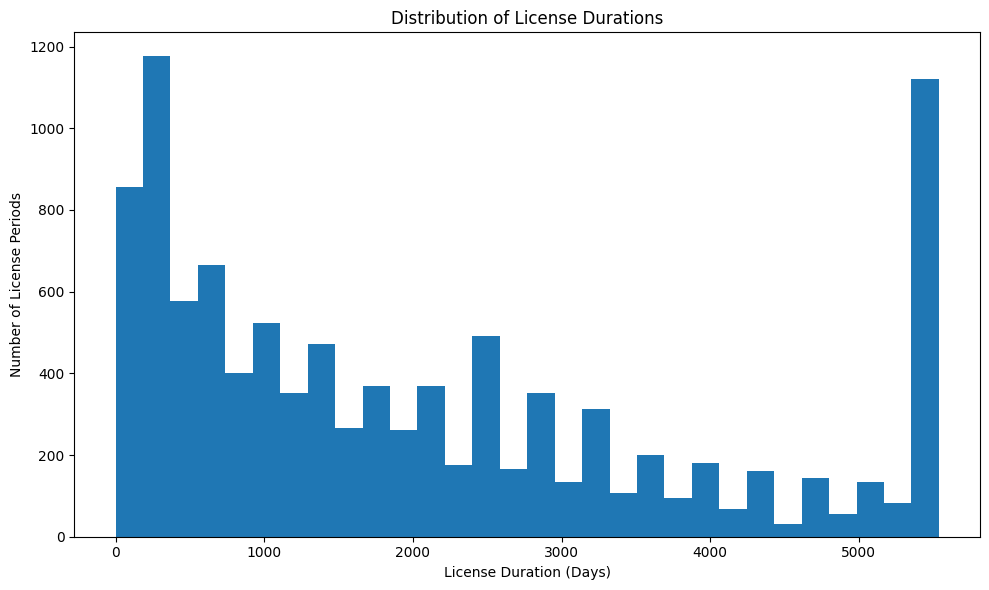

In [43]:
fig, ax = plt.subplots(figsize=(10, 6))

ax.hist(valid_licenses["duration_days"], bins=30)

ax.set_title("Distribution of License Durations")
ax.set_xlabel("License Duration (Days)")
ax.set_ylabel("Number of License Periods")

fig.tight_layout()

plt.savefig(
    "license_duration_histogram.png",
    dpi=300,
    bbox_inches="tight"
)

plt.show()